<a href="https://colab.research.google.com/github/LinaMariaCastro/curso-ia-para-economia/blob/main/clases/4_Aprendizaje_no_supervisado/1_Taller_Clustering_Pymes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Inteligencia Artificial con Aplicaciones en Economía I**

- 👩‍🏫 **Profesora:** [Lina María Castro](https://www.linkedin.com/in/lina-maria-castro)
- 📧 **Email:** [lmcastroco@gmail.com](mailto:lmcastroco@gmail.com)
- 🎓 **Universidad:** Universidad Externado de Colombia - Facultad de Economía

# 🏭 **Taller: Segmentación del Tejido Empresarial Colombiano**
---

**IMPORTANTE**: Guarda una copia de este notebook en tu Google Drive o computador.

**Taller en parejas.**

**Nombres estudiantes:**

- Andrés Felipe Linares
- Juan Pablo Lozano

**Forma de entrega:**

- Nombrar el archivo de la siguiente forma:“Taller_Clustering_apellidos.ipynb”.
- Suba el Jupyter Notebook a su cuenta en Github y envíe el link en el siguiente Forms: https://forms.cloud.microsoft/r/Nr3n9tg3fj.

**IMPORTANTE:** No se recibirán talleres en Google Colab, el notebook debe estar subido en Github.

**Plazo de entrega:**

16 de octubre de 2026, máximo a las 11:59 p.m. Tenga en cuenta que luego de esa hora el formulario en forms se cierra. El Jupupyter Notebook también debe quedar subido en Github antes de esa hora.

## 📄 Caso de Estudio: Consultoría para Bancóldex y el MinCIT

**Contexto:** Bancóldex y el Ministerio de Comercio, Industria y Turismo destinan cada año un presupuesto limitado a apoyar a las micro, pequeñas y medianas empresas del país. Hasta ahora han usado un **único paquete de instrumentos para todas**: la misma línea de crédito, el mismo programa de capacitación y la misma convocatoria de internacionalización, sin importar si la empresa es una tienda de barrio con tres empleados o una manufactura mediana con ciento cincuenta.

La evaluación de impacto del año pasado fue demoledora: el programa no movió la aguja en casi ningún indicador. La hipótesis del equipo técnico es que el problema no es el monto, sino la **focalización**: empresas con necesidades muy distintas están recibiendo exactamente lo mismo.

**Tu misión:** tu equipo de consultoría recibió una base con **250 empresas** y sus indicadores financieros, productivos y de internacionalización. Deben aplicar técnicas de **clustering** para descubrir si existen segmentos con perfiles diferenciados, caracterizar cada uno y proponer instrumentos de política específicos para ellos.

> **Ojo:** nadie les va a decir cuántos grupos hay ni cómo se llaman. Eso es precisamente lo que tienen que descubrir y **justificar** con los datos.

## 💾 Diccionario de datos — `pymes_colombia.csv`

| Columna | Tipo | Descripción |
|---|---|---|
| `empresa` | Texto | Código anonimizado de la empresa (`PYME_001`, …). **No entra al clustering.** |
| `ventas_anuales` | Numérica | Ventas del último año fiscal, en millones de pesos. |
| `empleados` | Numérica | Número de empleados con contrato vigente. |
| `productividad` | Numérica | Ventas por empleado, en millones de pesos. |
| `margen_operacional` | Numérica | Utilidad operacional sobre ventas (%). Puede ser negativo. |
| `endeudamiento` | Numérica | Pasivo total sobre activo total (%). |
| `exportaciones_pct` | Numérica | Porcentaje de las ventas destinado a mercados externos. |
| `inversion_tic` | Numérica | Inversión en tecnología como porcentaje de las ventas. |
| `antiguedad` | Numérica | Años desde la constitución legal de la empresa. |
| `crecimiento_ventas` | Numérica | Variación porcentual de las ventas frente al año anterior. |
| `sector` | Categórica | Agroindustria, Comercio, Manufactura, Servicios o TIC. |
| `region` | Categórica | Andina, Caribe, Eje Cafetero o Pacífica. |

## 📋 Instrucciones generales

- Completen el código en las celdas marcadas con `### TU CÓDIGO AQUÍ ###`. Pueden añadir todas las celdas que necesiten.
- **No modifiquen** la celda de verificación (la última celda de código del notebook).
- Usen **exactamente** los nombres de variables que pide cada enunciado: la verificación automática los busca por nombre. Un nombre mal escrito cuenta como punto perdido.
- Usen siempre `random_state=42` donde el enunciado lo pida, para que sus resultados sean reproducibles.
- Los ejercicios son **acumulativos**: el Ejercicio 5 usa lo que construyeron en el 3. Si un punto sale ❌, revísenlo antes de seguir.
- Ejecuten la **celda de verificación** las veces que quieran mientras trabajan: les dice en qué punto exacto está el error.

### ✅ Checklist de nombres exactos

| Ejercicio | Variables que busca la verificación |
|---|---|
| 1 | `df`, `n_nulos`, `conteo_sector`, `analisis_descriptivo` |
| 2 | `matriz_corr`, `analisis_correlaciones` |
| 3 | `X`, `scaler`, `X_scaled`, `varianzas_sin_escalar`, `clusters_sin_escalar`, `analisis_escala` |
| 4 | `wcss`, `silhouette_scores`, `analisis_codo`, `analisis_silueta`, `k_optimo`, `justificacion_k` |
| 5 | `kmeans`, columna `cluster_kmeans`, `perfil_clusters`, `silueta_final`, `centroides_originales`, `nombres_clusters`, `descripcion_clusters` |
| 6 | `df_mixto`, `matriz_mixta`, `indice_categoricas`, `kproto`, columna `cluster_kproto`, `comparacion`, `analisis_kprototypes` |
| 7 | `nuevas_scaled`, `clusters_nuevas`, `recomendaciones`, `limitaciones`, `validacion_negocio` |

---
# 🔍 **Ejercicio 1: Carga y exploración de los datos**

**1.0** Importa las librerías que vas a necesitar en todo el taller: `pandas`, `numpy`, `matplotlib.pyplot`, `seaborn`, y de `scikit-learn` el `StandardScaler`, el `KMeans` y el `silhouette_score`.

*(Este punto no tiene prueba automática, pero sin él no funciona nada de lo que sigue.)*

In [84]:
### TU CÓDIGO AQUÍ ###
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [85]:
# Configuraciones de visualización (ejecutar sin modificar)
pd.options.display.max_columns = None
pd.options.display.float_format = '{:,.2f}'.format
sns.set(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)

import warnings
warnings.filterwarnings('ignore')

### 📂 Llevar el archivo a Colab

`pymes_colombia.csv` tiene que quedar al alcance del notebook. Pueden arrastrarlo al panel de archivos 📁 de la izquierda, o montar su Drive con `from google.colab import drive; drive.mount('/content/drive')` y luego moverse a la carpeta con `os.chdir(...)`.

La celda siguiente comprueba que el archivo esté donde el notebook lo va a buscar.

**1.1** Carga el archivo `pymes_colombia.csv` en un DataFrame llamado `df` y muestra las **5 primeras filas**.

In [86]:
### TU CÓDIGO AQUÍ ###
from google.colab import drive
drive.mount('/content/drive')
path = '/content/drive/MyDrive/Curso_IA_20262/4_Aprendizaje_no_supervisado'
os.chdir(path)
df = pd.read_csv('pymes_colombia.csv')
df.head(5)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,empresa,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas,sector,region
0,PYME_001,"4,458.40",62,71.91,7.20,30.50,2.80,1.90,33,2.30,Comercio,Andina
1,PYME_002,406.50,6,67.75,5.50,44.30,0.10,1.20,10,-2.30,Comercio,Eje Cafetero
2,PYME_003,"4,447.20",48,92.65,7.50,50.90,5.30,1.10,25,5.40,Comercio,Andina
3,PYME_004,"16,455.90",119,138.28,-1.20,77.30,13.80,2.60,28,-8.00,Comercio,Pacífica
4,PYME_005,"16,413.80",203,80.86,-3.50,84.20,4.90,2.40,18,-14.50,Servicios,Andina


**1.2** Muestra la información general del DataFrame (tipos de dato, número de filas y columnas) y sus estadísticas descriptivas.

Además, guarda:

- en `n_nulos`, el **número total** de valores faltantes de toda la base (un solo número);
- en `conteo_sector`, el número de empresas de cada **sector**.

In [87]:
### TU CÓDIGO AQUÍ ###
df.shape

(250, 12)

In [88]:
### TU CÓDIGO AQUÍ ###
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   empresa             250 non-null    object 
 1   ventas_anuales      250 non-null    float64
 2   empleados           250 non-null    int64  
 3   productividad       250 non-null    float64
 4   margen_operacional  250 non-null    float64
 5   endeudamiento       250 non-null    float64
 6   exportaciones_pct   250 non-null    float64
 7   inversion_tic       250 non-null    float64
 8   antiguedad          250 non-null    int64  
 9   crecimiento_ventas  250 non-null    float64
 10  sector              250 non-null    object 
 11  region              250 non-null    object 
dtypes: float64(7), int64(2), object(3)
memory usage: 23.6+ KB


In [89]:
df.describe()

,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas
count,250.00,250.00,250.00,250.00,250.00,250.00,250.00,250.00,250.00
mean,"6,242.05",63.07,92.82,7.83,52.17,13.44,2.88,17.16,4.94
std,"5,547.71",56.20,39.72,7.27,17.29,18.34,2.97,9.98,10.93
min,66.70,2.00,8.34,-5.90,22.30,0.00,0.00,1.00,-17.30
25%,426.80,8.00,67.22,3.23,40.55,0.60,0.90,9.00,-0.20
50%,"4,694.50",55.00,87.17,6.85,47.10,3.85,1.70,16.00,3.20
75%,"10,491.10",81.75,114.13,12.00,59.15,16.45,3.08,26.00,8.25
max,"22,240.30",214.00,285.75,24.70,94.20,64.00,10.90,42.00,35.60


In [90]:
### TU CÓDIGO AQUÍ ###
n_nulos = df.isna().sum().sum()
print("Valores faltantes en toda la base:", n_nulos)
conteo_sector = df['sector'].value_counts()
print(conteo_sector)

Valores faltantes en toda la base: 0
sector
Comercio         75
Manufactura      64
Agroindustria    49
Servicios        43
TIC              19
Name: count, dtype: int64


**📝 A1. Análisis de las estadísticas descriptivas** *(pregunta abierta)*

Redacta un análisis de lo que acabas de ver. Responde por lo menos:

- ¿Hay valores nulos? ¿Hay que imputar algo antes de agrupar?
- ¿Las escalas de las variables son muy diferentes entre sí? Compara la desviación estándar de `ventas_anuales` con la de `margen_operacional`.
- ¿Qué implicaciones tiene eso para un algoritmo que trabaja con **distancias**?
- ¿Hay alguna variable cuyo mínimo o máximo te llame la atención desde el punto de vista económico?

In [91]:
analisis_descriptivo = """
La muestra no presenta valores nulos, por ende no es necesario realizar imputaciones a ninguna variable. Las escalas de las variables son muy distintas,
esto tiene todo el sentido ya que no es comparable la escala que tienen laqs ventas anuales con el numero de empleados por ejemplo. Luego la desviacion estandar entre
las ventas anaules y el margen operacional dista bastante, en la primera variable existe una desviacion muy alta (5547.71), mientras que en el margen operacional es bastante pequeña (7.27).
Afecta bastante y es necesario normalizar las variables realizando una transformacion. Luego de analizar los rangos extremos de las variables, no hay ninguna variable que nos llame especialmente la atencion.
"""

---
# 📊 **Ejercicio 2: ¿Qué relaciones hay entre las variables?**

Antes de agrupar conviene entender cómo se mueven juntas las variables. Si dos indicadores miden prácticamente lo mismo, estarían entrando dos veces al cálculo de la distancia.

**2.1** Calcula la matriz de correlación de las **nueve variables numéricas** (todas menos `empresa`, `sector` y `region`) y guárdala en `matriz_corr`. Después grafícala como un mapa de calor (`sns.heatmap`) con los valores anotados.

In [92]:
df_corr = df[['ventas_anuales', 'empleados', 'productividad', 'margen_operacional', 'endeudamiento', 'exportaciones_pct', 'inversion_tic', 'antiguedad', 'crecimiento_ventas']]
matriz_corr = df_corr.corr()
matriz_corr

,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas
ventas_anuales,1.00,0.93,0.43,-0.05,0.84,0.51,0.50,0.28,-0.08
empleados,0.93,1.00,0.17,-0.24,0.87,0.32,0.31,0.36,-0.28
productividad,0.43,0.17,1.00,0.43,0.20,0.56,0.57,0.03,0.42
margen_operacional,-0.05,-0.24,0.43,1.00,-0.33,0.67,0.70,-0.05,0.87
endeudamiento,0.84,0.87,0.20,-0.33,1.00,0.24,0.21,0.21,-0.33
exportaciones_pct,0.51,0.32,0.56,0.67,0.24,1.00,0.93,-0.15,0.71
inversion_tic,0.50,0.31,0.57,0.70,0.21,0.93,1.00,-0.09,0.72
antiguedad,0.28,0.36,0.03,-0.05,0.21,-0.15,-0.09,1.00,-0.23
crecimiento_ventas,-0.08,-0.28,0.42,0.87,-0.33,0.71,0.72,-0.23,1.00


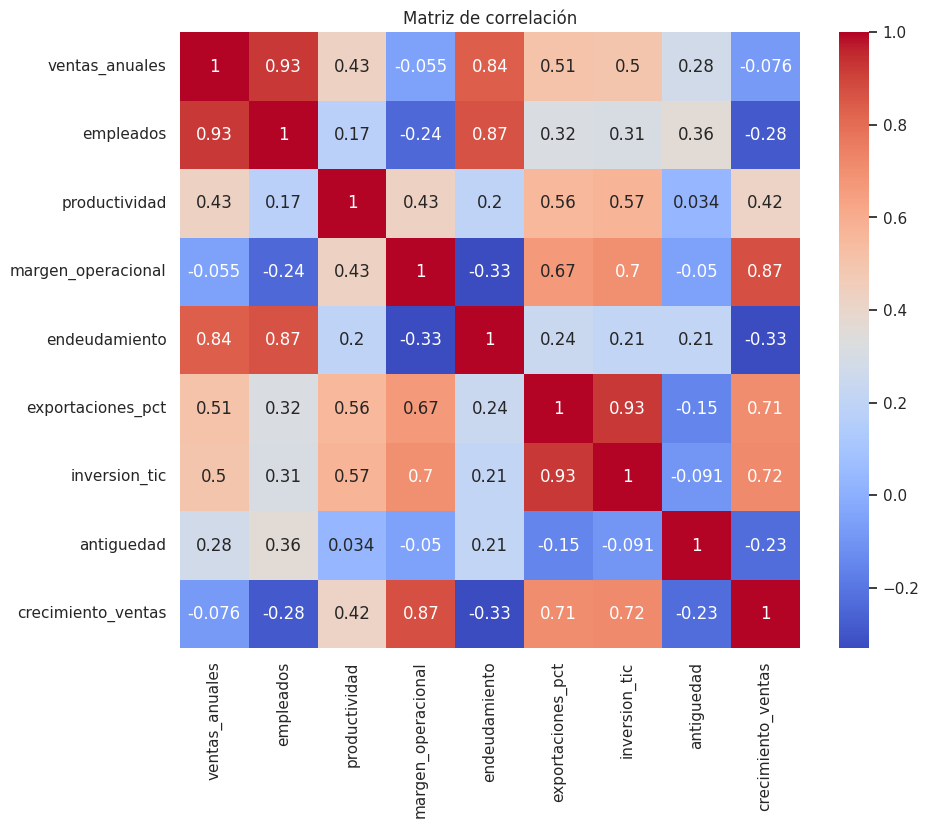

In [93]:
plt.figure(figsize=(10, 8))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm')
plt.title('Matriz de correlación')
plt.show()

**📝 A2. Lectura económica de las correlaciones** *(pregunta abierta)*

- ¿Cuál es el par de variables **más correlacionado positivamente**? ¿Tiene sentido económico?
- ¿Cuál es la correlación **negativa** más fuerte? ¿Qué historia cuenta sobre las empresas de la base?
- ¿Ves alguna pareja tan correlacionada que podrías sospechar redundancia? ¿Qué problema traería para el clustering?

In [94]:
analisis_correlaciones = """
La matriz muestra una alto nivel de correlacion entre las variables empleados y ventas anuales, de manera que tiene sentido económico, ya que el numero de empleados está directamente
relacionado con el tamaño de la empresa, y es de esperar que una empresa grande venda más.
Adicionalmente, existe una alta correlación entre inversión en tecnología y exportaciones, lo cual creemos no necesariamente tiene una relación económica, más que se evidencia que
para que una empresa pymes llegue al mercado internacional, tendría que invertir en tecnología.
Por otra parte, las correlaciones más negativas la presentan crecimiento de las ventas y el endeudamiento, durante el año registrado aquellos que mas se endeudaron
no necesariamente vieron un incremento en sus ventas respecto al año anterior.
Nos llama la atención la alta correlación entre inversión y exportaciones, ya que es la correalación más alta junto con ventas y empleados, lo cual podría deberse a que los
estandares de exportación en las economías internacionales sean más exigentes, lo que haría que sea necesario invertir en el desarrollo del producto.
"""

---
# ⚙️ **Ejercicio 3: Preprocesamiento y el efecto de la escala**

**3.1** Prepara los datos para el clustering:

1. Guarda en `X` **solo las nueve variables numéricas** (es decir, `df` sin `empresa`, `sector` ni `region`).
2. Crea un `StandardScaler` y guárdalo en una variable llamada `scaler` (lo vas a volver a necesitar en el Ejercicio 7).
3. Ajusta el `scaler` a `X` y guarda el resultado en `X_scaled`.
4. Imprime las 3 primeras filas de `X_scaled`.

In [95]:
X = df[['ventas_anuales', 'empleados', 'productividad', 'margen_operacional', 'endeudamiento', 'exportaciones_pct', 'inversion_tic', 'antiguedad', 'crecimiento_ventas']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)
X_scaled.head(3)

,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas
0,-0.32,-0.02,-0.53,-0.09,-1.26,-0.58,-0.33,1.59,-0.24
1,-1.05,-1.02,-0.63,-0.32,-0.46,-0.73,-0.57,-0.72,-0.66
2,-0.32,-0.27,-0.00,-0.05,-0.07,-0.44,-0.60,0.79,0.04


**3.2 ¿Y si no estandarizamos?** Vamos a comprobar con datos por qué el paso anterior no es opcional.

1. Guarda en `varianzas_sin_escalar` la **varianza de cada columna de `X`** (sin estandarizar), ordenada de mayor a menor. Imprímela.
2. Aplica K-Means **directamente sobre `X`, sin estandarizar**, con `n_clusters=5`, `init='k-means++'`, `n_init=10` y `random_state=42`. Guarda las etiquetas en `clusters_sin_escalar`.
3. Imprime cuántas empresas quedaron en cada grupo y el promedio de cada variable por grupo.

> El `k=5` de este punto es **provisional**: solo sirve para la comparación. En el Ejercicio 4 van a decidir el k de verdad.

In [96]:
### TU CÓDIGO AQUÍ ###
varianzas_sin_escalar = X.var().sort_values(ascending=False)
varianzas_sin_escalar

,0
ventas_anuales,"30,777,134.12"
empleados,"3,158.95"
productividad,"1,577.51"
exportaciones_pct,336.38
endeudamiento,298.94
crecimiento_ventas,119.45
antiguedad,99.55
margen_operacional,52.82
inversion_tic,8.84


In [97]:
kmeans = KMeans(n_clusters=5, init='k-means++', max_iter=300, n_init=10, random_state=42)
clusters_sin_escalar = kmeans.fit_predict(X)
clusters_sin_escalar


array([2, 1, 2, 3, 3, 2, 3, 1, 2, 0, 1, 1, 4, 1, 2, 1, 3, 4, 2, 1, 1, 1,
       4, 3, 1, 4, 1, 2, 2, 2, 1, 4, 1, 4, 3, 4, 2, 1, 1, 1, 3, 1, 3, 2,
       4, 2, 3, 4, 2, 1, 4, 2, 2, 2, 2, 2, 1, 1, 2, 2, 1, 1, 0, 1, 0, 4,
       4, 0, 1, 2, 2, 4, 2, 2, 1, 4, 4, 1, 0, 2, 2, 3, 2, 1, 2, 0, 1, 1,
       2, 2, 1, 1, 3, 0, 1, 2, 1, 2, 4, 4, 1, 1, 1, 4, 2, 1, 4, 1, 3, 2,
       2, 3, 2, 0, 2, 0, 4, 0, 3, 4, 3, 1, 4, 4, 2, 4, 2, 1, 4, 1, 3, 1,
       4, 2, 4, 4, 2, 3, 1, 4, 2, 1, 0, 2, 0, 2, 4, 1, 4, 2, 4, 4, 4, 2,
       1, 2, 2, 0, 4, 2, 1, 1, 4, 1, 0, 4, 4, 4, 2, 2, 1, 0, 1, 0, 0, 4,
       1, 2, 1, 1, 1, 0, 1, 1, 2, 0, 1, 1, 0, 1, 2, 4, 1, 0, 1, 2, 3, 1,
       4, 2, 2, 0, 2, 2, 4, 0, 1, 1, 1, 4, 2, 4, 0, 2, 1, 4, 1, 1, 1, 4,
       2, 2, 4, 4, 3, 1, 1, 2, 4, 1, 0, 1, 1, 3, 1, 2, 4, 2, 4, 1, 2, 1,
       2, 4, 2, 3, 1, 2, 2, 2], dtype=int32)

In [98]:
print(pd.Series(clusters_sin_escalar).value_counts().sort_index())

X_con_cluster = X.copy()
X_con_cluster['cluster'] = clusters_sin_escalar

print(X_con_cluster.groupby('cluster').mean())

0    25
1    79
2    72
3    21
4    53
Name: count, dtype: int64
         ventas_anuales  empleados  productividad  margen_operacional  \
cluster                                                                 
0             13,119.70     139.96         101.61                1.92   
1                361.92       6.42          67.86                4.61   
2              4,490.52      52.60          88.41                9.54   
3             17,568.06     177.05         101.01               -2.29   
4              9,654.36      80.30         128.64               17.11   

         endeudamiento  exportaciones_pct  inversion_tic  antiguedad  \
cluster                                                                
0                79.81              16.54           3.54       19.88   
1                39.46               0.45           0.63        7.34   
2                45.13               4.47           1.71       28.46   
3                83.81              12.16           2.42      

**📝 A3. El efecto de la escala** *(pregunta abierta)*

- ¿Qué variable concentra casi toda la varianza de `X` sin estandarizar? ¿Qué porcentaje de la varianza total representa?
- Mirando el perfil de los grupos de arriba: ¿qué variable está separando realmente a los grupos y cuáles está ignorando el algoritmo?
- Explica, con la fórmula de la distancia euclidiana en la cabeza, **por qué** ocurre esto.

In [99]:
analisis_escala = """
La variable que mas concentra la varianza de X es Ventas anuales y representa mas del 90% de la varianza total.
La variable que logra identificar los grupos con mayor fuerza es ventas anuales ya que su escala es muy alta.
Esto se ve reflejado precisamente con la distancia euclidiana, pues cada variable "aporta" en sus unidades
y ventas anuales es la variable que tiene las unidades mas altas, lo que genera que aporte mas a la generaciokn de los grupos.

"""

---
# 📐 **Ejercicio 4: ¿Cuántos segmentos hay? (elección de k)**

De aquí en adelante **se trabaja siempre sobre `X_scaled`**.

**4.1 Método del codo.** Para cada `k` de **1 a 10**, entrena un K-Means sobre `X_scaled` (con `init='k-means++'`, `n_init=10`, `random_state=42`) y guarda su inercia en una lista llamada `wcss`. Grafica la curva.

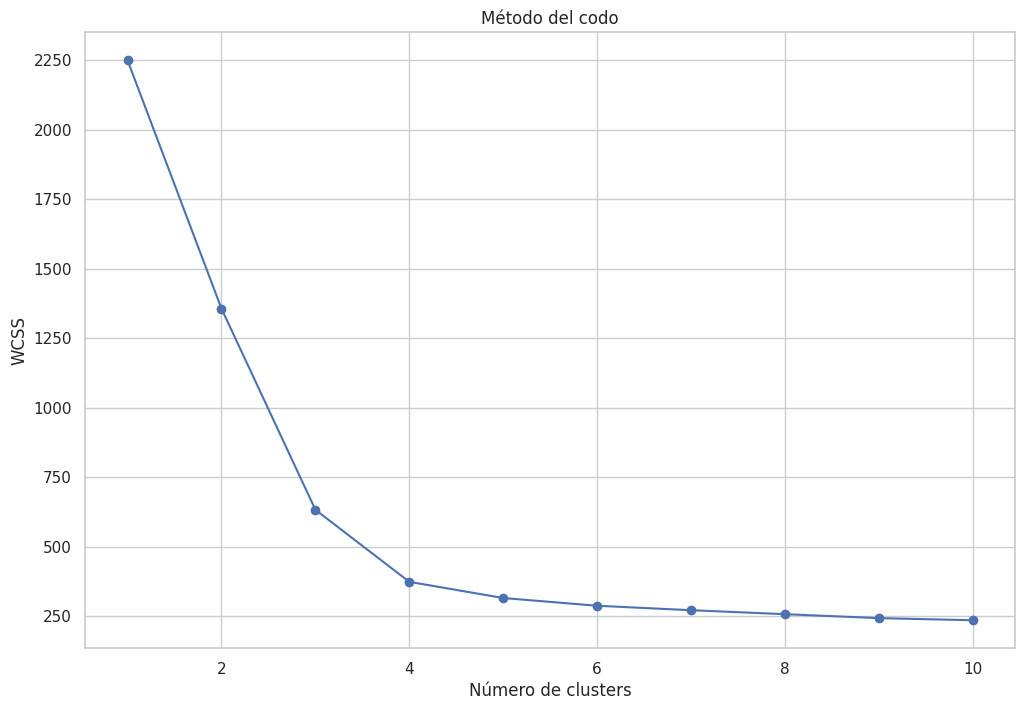

In [100]:
### TU CÓDIGO AQUÍ ###
wcss = []
for i in range (1,11):
  kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=42)
  kmeans.fit(X_scaled)
  wcss.append(kmeans.inertia_)

plt.plot(range(1,11), wcss, marker='o')
plt.title('Método del codo')
plt.xlabel('Número de clusters')
plt.ylabel('WCSS')
plt.show()

**📝 A4. Lectura del codo** *(pregunta abierta)*

¿Dónde está el "codo"? ¿Qué valores de k son candidatos razonables y cuáles quedan descartados? Apóyate en cuánto cae el WCSS al pasar de un k al siguiente.

In [101]:
analisis_codo = """
3 y 4 parecen ser valores razonables, descartando numéros superiores tienen inercia baja y numeros superiores están muy cerca del valor maximo de inercia.
"""

**4.2 Coeficiente de silueta.** Para cada `k` de **2 a 10**, entrena un K-Means sobre `X_scaled` (con `n_init=10` y `random_state=42`), calcula el `silhouette_score` y guárdalo en una lista llamada `silhouette_scores`. Imprime el valor de cada k y grafica la curva.

Para n_clusters = 2, el coeficiente de silueta promedio es: 0.4530
Para n_clusters = 3, el coeficiente de silueta promedio es: 0.5826
Para n_clusters = 4, el coeficiente de silueta promedio es: 0.5568
Para n_clusters = 5, el coeficiente de silueta promedio es: 0.5555
Para n_clusters = 6, el coeficiente de silueta promedio es: 0.4697
Para n_clusters = 7, el coeficiente de silueta promedio es: 0.3854
Para n_clusters = 8, el coeficiente de silueta promedio es: 0.3031
Para n_clusters = 9, el coeficiente de silueta promedio es: 0.2211
Para n_clusters = 10, el coeficiente de silueta promedio es: 0.2286


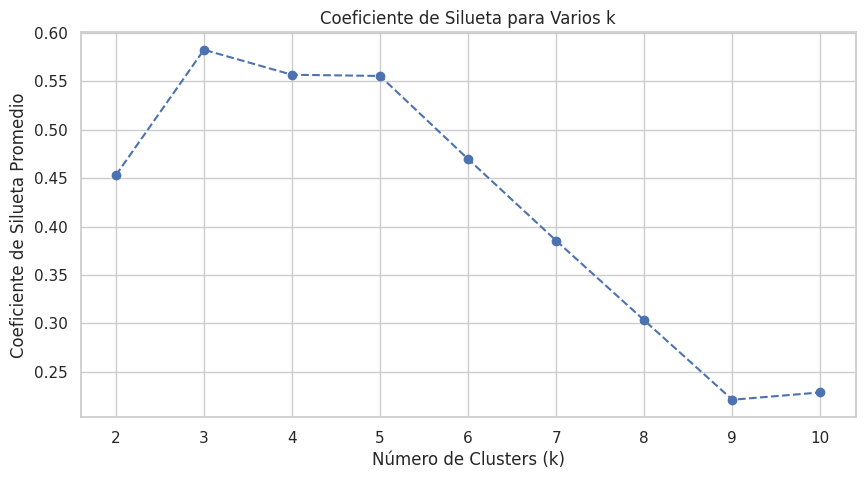

In [102]:
### TU CÓDIGO AQUÍ ###
range_n_clusters = range(2, 11)

silhouette_scores = []

for n_clusters in range_n_clusters:
    clusterer = KMeans(n_clusters=n_clusters, n_init=10, random_state=42)
    cluster_labels = clusterer.fit_predict(X_scaled)
    silhouette_avg = silhouette_score(X_scaled, cluster_labels)
    silhouette_scores.append(silhouette_avg)
    print(f"Para n_clusters = {n_clusters}, el coeficiente de silueta promedio es: {silhouette_avg:.4f}")

plt.figure(figsize=(10, 5))
plt.plot(range_n_clusters, silhouette_scores, marker='o', linestyle='--')
plt.title('Coeficiente de Silueta para Varios k')
plt.xlabel('Número de Clusters (k)')
plt.ylabel('Coeficiente de Silueta Promedio')
plt.show()

**📝 A5. Lectura de la silueta** *(pregunta abierta)*

¿Qué k maximiza el coeficiente de silueta? ¿Qué significa ese número (recuerda: cohesión y separación)? ¿El resultado **coincide** con el del método del codo o hay tensión entre los dos criterios?

In [103]:
analisis_silueta = """
Dado que el coeficiente de Silueta tiene un rango entre 1 y -1, siendo el numéro más cercano a 1 el ideal del coeficiente, el numero de 3 es el más cercano a este.
"""

**4.3 La decisión.** Con el codo y la silueta sobre la mesa, **tu equipo decide**: guarda en `k_optimo` el número de clusters que van a usar en el resto del taller.

> La verificación automática **acepta cualquier k razonable**; lo que se califica aquí es la **justificación**, no el número.

In [104]:
### TU CÓDIGO AQUÍ ###
k_optimo = 3
print("El equipo trabajará con k =", k_optimo)

El equipo trabajará con k = 3


**📝 A6. Justificación del k elegido** *(pregunta abierta)*

Justifiquen la decisión. No basta con decir "porque la silueta es más alta": expliquen cómo pesaron los dos criterios estadísticos **y** el criterio de utilidad para el cliente (¿cuántos programas distintos puede administrar razonablemente Bancóldex?).

In [105]:
justificacion_k = """
Ambos criterios arrojaron que el numero de grupos mas adecuado para la meustra es 3.
Luego este datos es coherente con lo que busca Bancoldex. Pues puede perfilar a sus clientes en 3
categorias: Alta necesidad, media necesidad, baja necesidad
"""

---
# 🎯 **Ejercicio 5: K-Means, perfilamiento e interpretación**

**5.1** Entrena el modelo definitivo:

1. Crea un `KMeans` con `n_clusters=k_optimo`, `init='k-means++'`, `n_init=10` y `random_state=42`, y guárdalo en una variable llamada `kmeans`.
2. Ajústalo sobre `X_scaled` y añade las etiquetas a `df` en una columna nueva llamada `cluster_kmeans`.
3. Imprime cuántas empresas quedaron en cada segmento y qué porcentaje del total representan.

In [106]:
### TU CÓDIGO AQUÍ ###
kmeans = KMeans(n_clusters=k_optimo, init='k-means++', max_iter=300, n_init=10, random_state=42)
clusters_kmeans = kmeans.fit_predict(X_scaled)

df['cluster_kmeans'] = clusters_kmeans

print(df['cluster_kmeans'].value_counts().sort_index())
print((df['cluster_kmeans'].value_counts(normalize=True).sort_index() * 100).round(2))

cluster_kmeans
0     57
1    149
2     44
Name: count, dtype: int64
cluster_kmeans
0   22.80
1   59.60
2   17.60
Name: proportion, dtype: float64


**5.2** Construye el **perfil** de los segmentos: guarda en `perfil_clusters` el **promedio de cada variable numérica** para cada cluster (las nueve variables de `X`, agrupadas por `cluster_kmeans`). Muéstralo.

In [107]:
### TU CÓDIGO AQUÍ ###
perfil_clusters = df.groupby('cluster_kmeans')[X.columns].mean()
perfil_clusters

,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas
cluster_kmeans,,,,,,,,,
0,"9,696.40",75.95,132.31,18.38,54.09,45.26,8.02,12.67,21.55
1,"2,274.83",27.80,77.55,6.80,41.99,1.76,1.07,17.54,2.99
2,"15,201.51",165.82,93.39,-2.35,84.18,11.78,2.36,21.73,-9.96


**5.3** Evalúa y visualiza la solución final:

1. Guarda en `silueta_final` el `silhouette_score` del modelo definitivo (calculado sobre `X_scaled` y la columna `cluster_kmeans`). Imprímelo.
2. Guarda en `centroides_originales` los centroides **devueltos a las unidades originales**, usando `scaler.inverse_transform(...)` sobre `kmeans.cluster_centers_`.
3. Haz un *scatter plot* de `exportaciones_pct` (eje X) contra `margen_operacional` (eje Y), coloreando por `cluster_kmeans`, y marca encima los centroides con una `X` roja grande.

> Pista para el gráfico: `centroides_originales` tiene las columnas en el mismo orden que `X`, así que `exportaciones_pct` es la columna 5 y `margen_operacional` la columna 3.

Silhouette Score: 0.5825898904201557


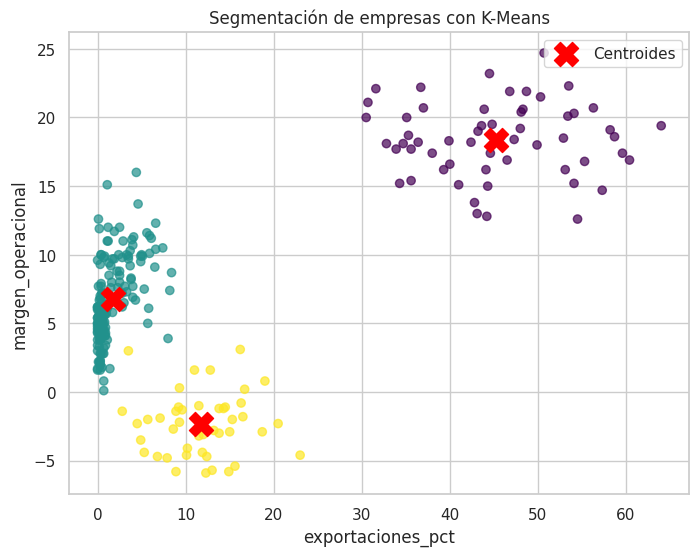

In [108]:
### TU CÓDIGO AQUÍ ###
silueta_final = silhouette_score(X_scaled, df['cluster_kmeans'])
print("Silhouette Score:", silueta_final)
centroides_originales = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(8, 6))

plt.scatter(df['exportaciones_pct'], df['margen_operacional'],
            c=df['cluster_kmeans'], cmap='viridis', alpha=0.7)

plt.scatter(centroides_originales[:, 5], centroides_originales[:, 3],
            s=300, c='red', marker='X', label='Centroides')

plt.title('Segmentación de empresas con K-Means')
plt.xlabel('exportaciones_pct')
plt.ylabel('margen_operacional')
plt.legend()
plt.show()

**5.4 Visualización complementaria.** Haz un segundo gráfico que te ayude a contar la historia: por ejemplo un `boxplot` de `endeudamiento` por cluster, o un *scatter* de `productividad` contra `crecimiento_ventas`.

*(Este punto no tiene prueba automática: se evalúa junto con el análisis escrito.)*

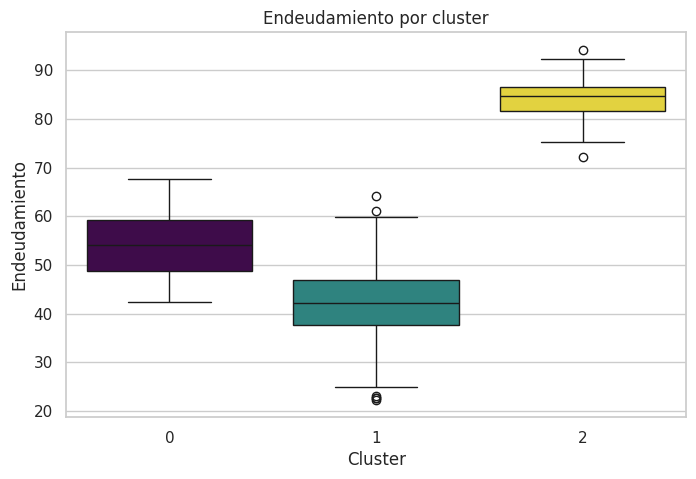

In [109]:
### TU CÓDIGO AQUÍ ###
plt.figure(figsize=(8, 5))
sns.boxplot(x='cluster_kmeans', y='endeudamiento', hue='cluster_kmeans', data=df, palette='viridis', legend=False)
plt.title('Endeudamiento por cluster')
plt.xlabel('Cluster')
plt.ylabel('Endeudamiento')
plt.show()

**📝 A7. Nombra los segmentos** *(pregunta abierta)*

Guarda en `nombres_clusters` una **lista de textos** con un nombre descriptivo para cada segmento, **en el orden de los clusters** (posición 0 = cluster 0, posición 1 = cluster 1, …). Deben ser tantos nombres como clusters elegiste.

Un buen nombre le dice al cliente qué es el grupo sin necesidad de mirar la tabla. En una segmentación de clientes de un banco, por ejemplo, *"Jóvenes con alta rotación de tarjeta"* es un buen nombre y *"Grupo 1"* no lo es.

In [110]:
nombres_clusters = [
    "Empresas con alta necesidad de capital",
    "Empresas con mediana necesidad de capital",
    "Empresas con baja necesidad de capital"
    # agrega tantos nombres como clusters hayas elegido
]

for i, nombre in enumerate(nombres_clusters):
    print("Cluster %d: %s" % (i, nombre))

Cluster 0: Empresas con alta necesidad de capital
Cluster 1: Empresas con mediana necesidad de capital
Cluster 2: Empresas con baja necesidad de capital


**📝 A8. Describe cada segmento** *(pregunta abierta)*

Para **cada** cluster, describe su perfil económico apoyándote en `perfil_clusters`: tamaño (ventas y empleados), productividad, rentabilidad, endeudamiento, vocación exportadora, inversión en tecnología, antigüedad y crecimiento. Menciona también **cuántas empresas** tiene y **qué porcentaje** del total representa.

Cierra con una frase por segmento: *¿cuál es el principal problema o la principal oportunidad de este grupo?*

In [111]:
descripcion_clusters = """
Cluster 0: Son empresas de tamaño mediano, con ventas promedio de 9.696 y unos 76 empleados.
Son el grupo mas rentable (18.4%) y productivo (132.3). Tienen la mayor vocacion exportadora (45.3%)
La mayor inversion en TIC (8.02) y el crecimiento de ventas mas algo (21.6%). Son tambien el
grupo con mas "jovenes" (12.7 años de antiguedad)
Oportunidad: Es el grupo que mejor combina tecnologia, exportaciones y rentabilidad y su potencia
de escalamiento es alto. Hay que cuidar que su crecimiento no lo financien con deuda.

Cluster 1: Es el grupo mas numeroso pero a su ves el mas pequeño. Tienen la menor productividad (77.6)
casi no exportan (1.8%) y casi no invierten en TIC (1.07).
Problema: Es un grupo con poca escala y baja tecnologia, orientado al mercado interno.

Cluster 2: Son las mas grandes en ventas y empleados. Su rentabilidad es negativa (-2.35%).
Tienen el endeudamiento mas alto (84.2%), ademas son las mas antiguas (21.7 años de antiguedad)
Problema: Tienen tamaño, pero con perdidas operativas, deuda muy alta y ventas en caida. Es el segmento
con mayor riesgo financiero
"""

In [112]:
print(resumen)
print(perfil_clusters.round(2))

                n_empresas  porcentaje (%)
cluster_kmeans                            
0                       57           22.80
1                      149           59.60
2                       44           17.60
                ventas_anuales  empleados  productividad  margen_operacional  \
cluster_kmeans                                                                 
0                     9,696.40      75.95         132.31               18.38   
1                     2,274.83      27.80          77.55                6.80   
2                    15,201.51     165.82          93.39               -2.35   

                endeudamiento  exportaciones_pct  inversion_tic  antiguedad  \
cluster_kmeans                                                                
0                       54.09              45.26           8.02       12.67   
1                       41.99               1.76           1.07       17.54   
2                       84.18              11.78           2.36     

---
# 🧩 **Ejercicio 6: ¿Y el sector? Clustering con variables mixtas (K-Prototypes)**

Hasta aquí dejamos por fuera `sector`, porque K-Means solo entiende números y la distancia euclidiana no sabe qué tan "lejos" está *Agroindustria* de *TIC*.

**K-Prototypes** resuelve el problema: usa la **media** como prototipo de las variables numéricas y la **moda** de las categóricas, y combina la distancia euclidiana con la distancia de Hamming.

In [113]:
!pip install kmodes --quiet

In [114]:
from kmodes.kprototypes import KPrototypes
from sklearn.preprocessing import LabelEncoder

**6.1** Prepara los datos mixtos. Sigue **exactamente** este orden de columnas, porque el algoritmo trabaja por posición:

1. Crea `df_mixto` como una copia de `df` con las **nueve variables numéricas de `X`** y, **al final**, la columna `sector`. (Es decir, 10 columnas en total, con `sector` en la última posición.)
2. Guarda en `indice_categoricas` la lista con la posición de la columna categórica dentro de `df_mixto`.
3. Convierte `df_mixto` a una matriz de NumPy y guárdala en `matriz_mixta`.
4. Estandariza **solo las nueve columnas numéricas** de `matriz_mixta` (posiciones 0 a 8), usando un `StandardScaler` **nuevo** (no reutilices `scaler`, que lo necesitas intacto para el Ejercicio 7).
5. Codifica la columna `sector` de `matriz_mixta` con `LabelEncoder`.
6. Imprime las 3 primeras filas de `matriz_mixta`.

In [115]:
### TU CÓDIGO AQUÍ ###
df_mixto = X.copy()
df_mixto['sector'] = df['sector']

indice_categoricas = [9]

matriz_mixta = df_mixto.values

scaler_mixto = StandardScaler()
matriz_mixta[:, 0:9] = scaler_mixto.fit_transform(matriz_mixta[:, 0:9])

le = LabelEncoder()
matriz_mixta[:, 9] = le.fit_transform(matriz_mixta[:, 9])

matriz_mixta[:3]

array([[-0.32215502244818983, -0.019040151619805316, -0.5276088744673821,
        -0.0871877106365195, -1.256085972320208, -0.5813621752210532,
        -0.3314103334258739, 1.5903486182423119, -0.2421498859617228, 1],
       [-1.0539930303588514, -1.0174001616470525, -0.6325576693059609,
        -0.3215632768637223, -0.45632651776549416, -0.7288716547061528,
        -0.5673615472156539, -0.7194529869340696, -0.6638860193192588, 1],
       [-0.3241779217518744, -0.26863015412661706, -0.004378584815428655,
        -0.04582731659642492, -0.07383286558715263, -0.4447793238459608,
        -0.6010688634713367, 0.7869393642679183, 0.04206359521400809, 1]],
      dtype=object)

**6.2** Aplica K-Prototypes con el **mismo `k_optimo`** que elegiste, usando `init='Cao'`, `n_init=5`, `verbose=0` y `random_state=42`. Guarda el modelo en `kproto` y las etiquetas en una columna nueva de `df` llamada `cluster_kproto`.

*(Este punto no tiene prueba automática, porque el resultado de `kmodes` puede variar entre versiones. Se evalúa con el análisis escrito.)*

In [116]:
### TU CÓDIGO AQUÍ ###
kproto = KPrototypes(n_clusters=k_optimo, init='Cao', n_init=5, verbose=0, random_state=42)
df['cluster_kproto'] = kproto.fit_predict(matriz_mixta, categorical = indice_categoricas)

**6.3** Compara las dos segmentaciones:

1. Guarda en `comparacion` una tabla cruzada (`pd.crosstab`) entre `cluster_kmeans` y `cluster_kproto`. Muéstrala.
2. Muestra también el perfil de los clusters de K-Prototypes: el promedio de las variables numéricas y la **moda** de `sector` para cada grupo.

In [117]:
### TU CÓDIGO AQUÍ ###
comparacion = pd.crosstab(df['cluster_kmeans'], df['cluster_kproto'])
comparacion

cluster_kproto,0,1,2
cluster_kmeans,,,
0,0,0,57
1,149,0,0
2,0,44,0


**📝 A9. ¿Qué aporta incluir el sector?** *(pregunta abierta)*

- Mirando `comparacion`: ¿los dos algoritmos encontraron prácticamente los mismos grupos o cambiaron de forma importante?
- ¿Qué **añade** (o qué **no** añade) la variable `sector` a la segmentación? ¿Por qué crees que ocurre eso con esta base en particular?
- ¿En qué situación de negocio **sí** valdría la pena usar K-Prototypes en lugar de K-Means?

In [118]:
analisis_kprototypes = """
Mirando la comparación entre los dos algoritmos se puede evidenciar que son practicamnte los mismos grupos, ya que la cantidad para cada cluster de cluster_kmeans
es igual a cluster_kproto, por lo que unicamente se adaptaron en cada nuevo cluster.
La variable sector no agrego una nueva segmentación, ya que los grupos permanecieron igual, por lo que se puede concluir que no es determinante para diferencias las empresas,
podría deberse a que las empresas ya están muy segmentadas entre sí, en el numero de clusters optimo.
"""

---
# 🏢 **Ejercicio 7: Poner el modelo a trabajar**

Bancóldex acaba de recibir tres solicitudes nuevas. Necesitan saber **a qué segmento pertenece cada una** para dirigirlas al programa correcto, sin volver a correr todo el análisis.

In [119]:
# Las tres empresas que acaban de postularse (ejecutar sin modificar)
nuevas_empresas = pd.DataFrame(
    {
        'ventas_anuales':     [11200.0,   280.0, 17800.0],
        'empleados':          [     68,       5,     171],
        'productividad':      [ 164.71,   56.00,  104.09],
        'margen_operacional': [   19.4,     3.8,    -3.1],
        'endeudamiento':      [   49.5,    36.2,    88.7],
        'exportaciones_pct':  [   52.0,     0.0,     9.8],
        'inversion_tic':      [    8.6,     0.5,     2.0],
        'antiguedad':         [     11,       6,      24],
        'crecimiento_ventas': [   24.5,     1.9,   -11.2],
    },
    index=['Solicitud A', 'Solicitud B', 'Solicitud C'],
)
nuevas_empresas

,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas
Solicitud A,"11,200.00",68,164.71,19.40,49.50,52.00,8.60,11,24.50
Solicitud B,280.00,5,56.00,3.80,36.20,0.00,0.50,6,1.90
Solicitud C,"17,800.00",171,104.09,-3.10,88.70,9.80,2.00,24,-11.20


**7.1** Clasifica las tres solicitudes:

1. Estandariza `nuevas_empresas` con el `scaler` **que ya entrenaste** en el Ejercicio 3 y guarda el resultado en `nuevas_scaled`.
2. Usa `kmeans.predict(...)` para obtener el cluster de cada una y guárdalo en `clusters_nuevas`.
3. Imprime, para cada solicitud, el cluster asignado y el nombre que le pusiste a ese segmento en `nombres_clusters`.

> ⚠️ **Trampa clásica:** aquí se usa `scaler.transform(...)`, **no** `fit_transform(...)`. Piensa por qué: si vuelves a ajustar el escalador con tres empresas, estarías midiéndolas contra el promedio de esas tres y no contra el de las 250 de la base.

In [120]:
### TU CÓDIGO AQUÍ ###
nuevas_scaled = scaler.transform(nuevas_empresas)

clusters_nuevas = kmeans.predict(nuevas_scaled)

for empresa, cluster in zip(nuevas_empresas.index, clusters_nuevas):
    print(empresa, cluster, nombres_clusters[cluster])


Solicitud A 0 Empresas con alta necesidad de capital
Solicitud B 1 Empresas con mediana necesidad de capital
Solicitud C 2 Empresas con baja necesidad de capital


**📝 A10. Recomendaciones de política** *(pregunta abierta)*

Guarda en `recomendaciones` una **lista de textos**, una recomendación por segmento. Cada una debe decir:

- a **qué segmento** va dirigida,
- **qué instrumento** concreto propones (línea de crédito, garantía, subsidio, asistencia técnica, programa de internacionalización, reestructuración de pasivos…),
- **por qué ese instrumento y no otro**, citando los números del perfil del grupo,
- **qué indicador** usarías para saber si funcionó.

In [121]:
recomendaciones = [
    "### Para el primer segmento, que son las 57 empresas del cluster 0, empresas que destacan por ser en promedio las más nuevas, con mayor margen, productividad, con más exportaciones e inversión; son empresas dinamicas que ya presentan indicadores que indican un buen comportamiento en el mercado, por lo que podría ser viable financiar más el apalancamiento para aprovechar sus indicadores de productividad y tecnología.###",
    "### Para el segundo segmento, que son la mayoria de empresas, las más antiguas, pequeñas y con peores indicadores, por lo que es dificil proporcionar apalancamiento, ya que son muy riesgosas, por lo que la politica publica puede ir enfocada en se prioriza mejorar sus capacidades productivas y subsidiar capacitación adicional ###",
    "### Para el ultimo segmento, que destacan en el año fiscal evaluado ser las peores con indicadores financieros, siendo las que tuvieron margen negativo, crecimineto negativo de las ventas y mayor endeudamiento; son empresas que a su vez, son las más grandes y antiguas en el mercado, la politica publica debe ir enfocada en mejorar su situación financiera, se propone un programa de reestructuración de pasivos y acompañamiento financiero ###"
]

for r in recomendaciones:
    print("-", r)

- ### RECOMENDACIÓN PARA EL PRIMER SEGMENTO ###
- ### RECOMENDACIÓN PARA EL SEGUNDO SEGMENTO ###


**📝 A11. Limitaciones del análisis** *(pregunta abierta)*

Antes de entregarle esto a un cliente hay que ser honesto sobre lo que el método **no** puede decir. Discute al menos cuatro limitaciones. Algunas pistas:

- ¿Qué supone K-Means sobre la **forma** de los grupos?
- ¿Qué pasa con las empresas que quedan **en la frontera** entre dos clusters?
- ¿Los segmentos que encontraste son un **hecho** de la economía colombiana o un **resultado** de las variables que te dieron y del k que elegiste?
- ¿Puedes concluir que el endeudamiento **causa** la caída de las ventas?
- ¿Qué pasaría si repitieras el ejercicio el año entrante?

In [122]:
limitaciones = """
K-Means agrupa las empresas según sus distancias a los centroides y funciona mejor cuando los grupos son relativamente compactos.
Por tanto, podría no identificar adecuadamente segmentos con formas más complejas o empresas con características atípicas.
Los tres grupos identificados son categorías muy marcadas a nivel nacional, evidenciado en el contraste con el modelo K-Prototypes,
y para la muestra se queda corto para profunidzar en el analisis, desde otras divisiones o con caracteristicas categoricas.
"""

**📝 A12. ¿Cómo validarías los segmentos con el cliente?** *(pregunta abierta)*

Un clustering estadísticamente impecable puede ser inútil en la práctica. Antes de que Bancóldex rediseñe sus programas, ¿cómo comprobarías que estos segmentos sirven? Piensa en:

- evidencia adicional que pedirías (otras variables, otros años, opinión de los analistas de crédito);
- alguna prueba **cuantitativa** que se pueda hacer con los datos;
- cómo harías el piloto antes de escalar el programa a todo el país.

In [123]:
validacion_negocio = """
Nos parece fundamental profundizar en información financiera, como puede ser flujos de caja, historial crediticio, ect. y considerando mayores rangos de tiempo para analizar la evolución de la empresa
para alguna prueba cuantitativa, Finalmente, propondríamos un programa piloto con empresas de los tres segmentos, aplicando a cada uno los instrumentos recomendados.
Se compararía su evolución con la de empresas similares que no reciban inicialmente la intervención, procurando que los grupos sean comparables.
"""

---
# ✅ Antes de entregar

1. Ejecuten el notebook completo de principio a fin (`Entorno de ejecución → Reiniciar y ejecutar todo`) y revisen que la celda de verificación llegue a **12 de 12**.
2. Revisen que las **12 preguntas abiertas** estén respondidas y que ninguna conserve el texto de ejemplo.
3. Escriban sus nombres al principio del notebook.
4. Súbanlo a GitHub y envíen el link en el formulario.

---
## 🤖 Verificación automática

Ejecuta esta celda cuando quieras: te dice cuántos de los 12 puntos de código llevas y **en cuál punto exacto** está el error.

**No modifiques esta celda.**

In [124]:
# =============================================================================
#  VERIFICACIÓN AUTOMÁTICA DEL TALLER DE CLUSTERING  ·  no modifiquen esta celda
# =============================================================================
import hashlib

import numpy as _np
import pandas as _pd

_SAL = b"extdo-clustering-pymes-2026-II"
_ITERACIONES = 60_000


def _canon(x):
    """Convierte cualquier resultado (incluidos objetos de NumPy y pandas) en un
    texto único y estable, para poder compararlo sin revelar la respuesta."""
    if x is None:
        return "N"
    if isinstance(x, (bool, _np.bool_)):
        return "B" + str(bool(x))
    if isinstance(x, _np.generic):            # np.float64, np.int64, np.str_...
        return _canon(x.item())
    if isinstance(x, (int, float)):           # int y float se tratan igual
        v = float(x)
        if v != v or v in (float("inf"), float("-inf")):
            return "X" + str(v)
        if v == 0:                            # -0.0 y 0.0 son el mismo valor
            v = 0.0
        return "#" + ("%.6g" % v)
    if isinstance(x, str):
        return "S" + x.strip()
    if isinstance(x, _pd.DataFrame):
        return ("DF[" + _canon(list(x.columns)) + ";" + _canon(list(x.shape))
                + ";" + _canon(x.to_dict()) + "]")
    if isinstance(x, _pd.Series):
        return "SE[" + ",".join(sorted(_canon(k) + "=" + _canon(v) for k, v in x.items())) + "]"
    if isinstance(x, (_pd.Index, _pd.Categorical)):
        return _canon(list(x))
    if isinstance(x, dict):
        return "D[" + ",".join(sorted(_canon(k) + "=" + _canon(v) for k, v in x.items())) + "]"
    if isinstance(x, (set, frozenset)):
        return "C[" + ",".join(sorted(_canon(i) for i in x)) + "]"
    if isinstance(x, _np.ndarray):
        return _canon(x.tolist())
    if isinstance(x, (list, tuple)):
        return "L[" + ",".join(_canon(i) for i in x) + "]"
    return "O" + repr(x)


def _huella(clave, valor):
    """Huella lenta a propósito (~60.000 iteraciones): verificar el notebook
    cuesta un par de segundos, pero adivinar la respuesta probando candidatos
    se vuelve inviable."""
    mensaje = (str(clave) + "|" + _canon(valor)).encode("utf-8")
    return hashlib.pbkdf2_hmac("sha256", mensaje, _SAL, _ITERACIONES).hex()[:16]


_EJERCICIOS = {
    "1": "Ejercicio 1 · Carga y exploración",
    "2": "Ejercicio 2 · Relaciones entre variables",
    "3": "Ejercicio 3 · Preprocesamiento y escala",
    "4": "Ejercicio 4 · Elección de k",
    "5": "Ejercicio 5 · K-Means e interpretación",
    "6": "Ejercicio 6 · K-Prototypes con el sector",
    "7": "Ejercicio 7 · El modelo en producción",
    "A": "Análisis escrito (lo califica la profesora)",
}

#  (punto, título, huellas aceptadas, cómo se obtiene el resultado, pista si falla)
#  Varias huellas en un mismo punto = ese punto depende del k que eligió el grupo,
#  y se acepta cualquier k razonable.
_PRUEBAS = [
    ("1.1", "Base cargada correctamente",
     ("21fef5bc81646de8",),
     lambda: [len(df), sorted(str(c) for c in df.columns if c not in ('cluster_kmeans', 'cluster_kproto')), round(float(df['ventas_anuales'].sum()), 2), round(float(df['productividad'].mean()), 4)],
     "Carga pymes_colombia.csv completo en df, sin cambiar ni renombrar columnas."),
    ("1.2", "Nulos totales y empresas por sector",
     ("82750ec4ed2c94b8",),
     lambda: [int(n_nulos), conteo_sector, round(float(df['endeudamiento'].std()), 4), round(float(df['crecimiento_ventas'].sum()), 2)],
     "n_nulos debe ser UN solo número (el total de toda la base, no una serie por columna) y conteo_sector el número de empresas de cada sector."),
    ("2.1", "Matriz de correlación de las 9 variables numéricas",
     ("285dd981a1169572",),
     lambda: [list(matriz_corr.shape), sorted(str(c) for c in matriz_corr.columns), round(float(matriz_corr.values.sum()), 4), round(float(matriz_corr.loc['exportaciones_pct', 'inversion_tic']), 4)],
     "La matriz debe ser de 9x9: calcúlala sobre df sin las columnas empresa, sector y region."),
    ("3.1", "Variables seleccionadas y estandarizadas",
     ("f92a6704ca04b713",),
     lambda: [list(X.shape), list(str(c) for c in X.columns), _np.round(_np.asarray(X_scaled)[[0, 124, 249]].astype(float), 4).tolist(), round(float(_np.asarray(X_scaled).astype(float).std(axis=0).mean()), 4)],
     "X son las 9 variables numéricas en el mismo orden del CSV, y X_scaled el resultado de scaler.fit_transform(X) con StandardScaler."),
    ("3.2", "Efecto de no estandarizar",
     ("fd58a9cae8024db2",),
     lambda: [varianzas_sin_escalar.round(2), sorted(_pd.Series(clusters_sin_escalar).value_counts().tolist())],
     "varianzas_sin_escalar es X.var() ordenada de mayor a menor, SIN estandarizar. Y el K-Means de este punto va sobre X (no sobre X_scaled), con n_clusters=5 y random_state=42."),
    ("4.1", "Método del codo (lista wcss)",
     ("187dc591a56295c4",),
     lambda: [len(wcss), [round(float(w), 1) for w in wcss[:4]]],
     "wcss debe tener 10 elementos, uno por cada k de 1 a 10, calculados sobre X_scaled con init='k-means++', n_init=10 y random_state=42."),
    ("4.2", "Coeficiente de silueta (lista silhouette_scores)",
     ("919b9299063407be",),
     lambda: [len(silhouette_scores), [round(float(s), 3) for s in silhouette_scores[:3]]],
     "silhouette_scores debe tener 9 elementos, uno por cada k de 2 a 10 (el de k=1 no existe), calculados sobre X_scaled con n_init=10 y random_state=42."),
    ("5.1", "K-Means final entrenado y etiquetas en df",
     ("24f380947694aec1",
      "258e920d08bbb80d",
      "2fb2013e4e3509a5",
      "372fb663109bf318",
      "574c75782e77ad46",
      "6be856106fbdcda5",
      "6bfbf5d142555c44",
      "6d02591e9b9d5e26",
      "6e0acaefac230acb",
      "708333a8476d9391",
      "77a8eca15b3af411",
      "bd93646c2d0857b2",
      "c9c3df5fd40dec82",
      "d7e3a0237cd8f9c5",
      "e1ebb665316f06ec",
      "e353fdfe72ca578d",
      "f0776e5ea1888707",
      "f8a1841da48619c0",
      "fb2ada8f7c034bc1",),
     lambda: [int(kmeans.n_clusters), sorted(df['cluster_kmeans'].value_counts().tolist()), round(float(kmeans.inertia_), 2)],
     "Entrena el KMeans sobre X_scaled (no sobre X) con n_clusters=k_optimo, init='k-means++', n_init=10 y random_state=42, y guarda las etiquetas en la columna cluster_kmeans."),
    ("5.2", "Perfil promedio de cada segmento",
     ("007f3c93c7f18d27",
      "086fdc54cd79ad3d",
      "09e4dd4038c94295",
      "154968e4e20c4318",
      "2347c1fe3638bf15",
      "2ba5fb2303ac9953",
      "36f5183f48d160ff",
      "3fc03de0f4d3e596",
      "5b276874eb928612",
      "5bb823c96e30905b",
      "658160ce6688e786",
      "70cd7218b47402f3",
      "710467cade4edfd1",
      "71c4a9e81b4814a2",
      "789cfad86e29abec",
      "9fb865f5a6c33245",
      "c1e12b3851aa2e6b",
      "d2ae8c4c8225cfa9",
      "f31afdb6867c34cd",),
     lambda: perfil_clusters[list(X.columns)].sort_values('ventas_anuales').round(2).reset_index(drop=True),
     "perfil_clusters es el promedio de las 9 variables numéricas por cluster: agrupa df por cluster_kmeans y saca la media (sin incluir la columna del cluster como variable)."),
    ("5.3", "Silueta final y centroides en unidades originales",
     ("09168179481bef61",
      "0f1e36ac8868d6dc",
      "1ddad4ae3e7f88fe",
      "1fbd083bce7876dc",
      "2088e4fc5f6a04f4",
      "323d53fe8ea9ef14",
      "5e57994b1d33180e",
      "6e7b610567f528ff",
      "75bd91c26d723274",
      "7ff38cf016a428a1",
      "828eae0a37c0380a",
      "89e0f52d134717f4",
      "8eb8dbd75d929748",
      "a4065bd17f293581",
      "af04f027742ddf20",
      "c66c1549743c8f86",
      "cce04f8707bbf862",
      "e65f6674e360f686",
      "f6f8a38aa037f177",),
     lambda: [round(float(silueta_final), 4), sorted(_np.round(_np.asarray(centroides_originales).astype(float).sum(axis=1), 2).tolist())],
     "silueta_final se calcula con silhouette_score(X_scaled, df['cluster_kmeans']), y centroides_originales con scaler.inverse_transform(kmeans.cluster_centers_)."),
    ("6.1", "Matriz mixta lista para K-Prototypes",
     ("0b410a9134798752",),
     lambda: [list(matriz_mixta.shape), list(indice_categoricas), _np.round(_np.asarray(matriz_mixta)[[0, 249], 0:9].astype(float), 4).tolist(), sorted(set(int(v) for v in _np.asarray(matriz_mixta)[:, 9]))],
     "matriz_mixta debe tener 10 columnas: las 9 numéricas estandarizadas (posiciones 0 a 8) y sector codificado con LabelEncoder en la posición 9. Ojo: se estandarizan SOLO las columnas 0 a 8."),
    ("7.1", "Clasificación de las tres solicitudes nuevas",
     ("03302f50031433ff",
      "1e13fdecc4336ff4",
      "1f79a01084c7c6f0",
      "290632fbf05d045d",
      "30a98799190e1832",
      "310552a89751795f",
      "35f952ef56b9cf62",
      "4a0fde5682b487a6",
      "717b25e9dd59eb3a",
      "725cd858e4df65de",
      "904a2b388895a5c1",
      "a06c07f13bc53402",
      "ad5e099e9a4c1de0",
      "b676daa74a43c5bb",
      "bcf4af1b6870a60a",
      "efba0673f79857e2",
      "f5e15685c5b55293",),
     lambda: [[round(float(perfil_clusters.loc[c, 'ventas_anuales']), 2) for c in clusters_nuevas], _np.round(_np.asarray(nuevas_scaled).astype(float), 3).tolist()],
     "Usa scaler.transform(nuevas_empresas) —NO fit_transform— y luego kmeans.predict(). Este punto también depende de que perfil_clusters (punto 5.2) esté bien."),
]

#  Puntos de análisis escrito: valen 8 puntos y los califica la profesora.
#  Aquí solo se comprueba que el grupo haya escrito algo.
_REVISION = [
    ("A1", "Análisis de las estadísticas descriptivas", lambda: analisis_descriptivo, "texto", 350),
    ("A2", "Lectura económica de las correlaciones", lambda: analisis_correlaciones, "texto", 300),
    ("A3", "El efecto de la escala", lambda: analisis_escala, "texto", 300),
    ("A4", "Lectura del método del codo", lambda: analisis_codo, "texto", 200),
    ("A5", "Lectura del coeficiente de silueta", lambda: analisis_silueta, "texto", 200),
    ("A6", "Justificación del k elegido", lambda: justificacion_k, "texto", 250),
    ("A7", "Nombres de los segmentos", lambda: nombres_clusters, "nombres", 3),
    ("A8", "Descripción de cada segmento", lambda: descripcion_clusters, "texto", 600),
    ("A9", "Aporte de K-Prototypes y del sector", lambda: analisis_kprototypes, "texto", 350),
    ("A10", "Recomendaciones de política", lambda: recomendaciones, "lista", 3),
    ("A11", "Limitaciones del análisis", lambda: limitaciones, "texto", 400),
    ("A12", "Validación de los segmentos con el cliente", lambda: validacion_negocio, "texto", 300),
]


def _estado_de(prueba):
    clave, _titulo, esperadas, obtener, _pista = prueba
    try:
        return "ok" if _huella(clave, obtener()) in esperadas else "mal"
    except NameError:
        return "falta"
    except Exception:
        return "error"


def _estado_revision(item):
    _clave, _titulo, obtener, tipo, minimo = item
    try:
        valor = obtener()
    except NameError:
        return "falta", "todavía no la has creado"
    except Exception:
        return "error", "no se pudo leer"

    if tipo == "texto":
        if not isinstance(valor, str):
            return "mal", "debe ser un texto entre comillas"
        texto = valor.strip()
        if "TU TEXTO AQUÍ" in texto or "###" in texto:
            return "falta", "sigue con el texto de ejemplo"
        if len(texto) < minimo:
            return "mal", "van %d caracteres de %d" % (len(texto), minimo)
        return "ok", "%d caracteres" % len(texto)

    if not isinstance(valor, (list, tuple)):
        return "mal", "debe ser una lista de textos"

    largo_minimo = 8 if tipo == "nombres" else 60
    utiles = [t for t in valor
              if isinstance(t, str) and len(t.strip()) >= largo_minimo and "###" not in t]
    if not utiles:
        return "falta", "sigue con la lista de ejemplo"
    if len(utiles) < minimo:
        return "mal", "van %d de %d (mínimo %d caracteres cada uno)" % (
            len(utiles), minimo, largo_minimo)
    return "ok", "%d elementos" % len(utiles)


_ICONO = {"ok": "\u2705", "mal": "\u274c", "falta": "\u23f3", "error": "\u26a0\ufe0f"}


def verificar_taller():
    resultados = [(p, _estado_de(p)) for p in _PRUEBAS]

    print("=" * 68)
    print("  VERIFICACIÓN AUTOMÁTICA · TALLER DE CLUSTERING")
    print("=" * 68)

    ejercicio_actual = None
    for (clave, titulo, _esp, _obt, _pista), estado in resultados:
        ejercicio = clave.split(".")[0]
        if ejercicio != ejercicio_actual:
            ejercicio_actual = ejercicio
            print("\n  " + _EJERCICIOS[ejercicio])
        print("    %s  %-5s %s" % (_ICONO[estado], clave, titulo))

    correctos = sum(1 for _p, e in resultados if e == "ok")
    total = len(resultados)
    llenas = round(20 * correctos / total)
    barra = "\u2588" * llenas + "\u2591" * (20 - llenas)

    print("\n" + "-" * 68)
    print("  CÓDIGO: %d de %d puntos automáticos" % (correctos, total))
    print("  [%s]" % barra)
    print("-" * 68)

    pendientes = [(c, t, e, pi) for (c, t, _e2, _o, pi), e in resultados if e != "ok"]
    if not pendientes:
        print("  🎉 ¡Los 12 puntos de código están completos!")
    else:
        print("  Qué falta por revisar (los %d primeros):\n" % min(len(pendientes), 5))
        for clave, titulo, estado, pista in pendientes[:5]:
            if estado == "falta":
                print("   ⏳ %s  %s" % (clave, titulo))
                print("      Aún no existe alguna de las variables que pide este punto.")
            elif estado == "error":
                print("   ⚠️  %s  %s" % (clave, titulo))
                print("      La variable existe pero algo falla al calcularla.")
            else:
                print("   ❌ %s  %s" % (clave, titulo))
            print("      Pista: %s\n" % pista)
        if len(pendientes) > 5:
            print("   ... y %d punto(s) más. Arregla estos primero: los ejercicios son"
                  " acumulativos y unos arrastran a otros.\n" % (len(pendientes) - 5))

    print("-" * 68)
    print("  📝 ANÁLISIS ESCRITO · 8 puntos que califica la profesora")
    print("     Aquí solo se comprueba que hayan escrito algo; el contenido lo")
    print("     evalúa la profesora. Escribir mucho no da puntos por sí solo.\n")
    escritos = 0
    for item in _REVISION:
        estado, detalle = _estado_revision(item)
        escritos += (estado == "ok")
        print("    %s  %-5s %-45s %s" % (_ICONO[estado], item[0], item[1], detalle))

    print("\n  Preguntas abiertas respondidas: %d de %d" % (escritos, len(_REVISION)))
    print("=" * 68)
    print("  NOTA AUTOMÁTICA (solo código): %.1f de 12 puntos" % (12.0 * correctos / total))
    print("  + hasta 8 puntos de análisis escrito que asigna la profesora.")
    print("=" * 68)


verificar_taller()


  VERIFICACIÓN AUTOMÁTICA · TALLER DE CLUSTERING

  Ejercicio 1 · Carga y exploración
    ✅  1.1   Base cargada correctamente
    ✅  1.2   Nulos totales y empresas por sector

  Ejercicio 2 · Relaciones entre variables
    ✅  2.1   Matriz de correlación de las 9 variables numéricas

  Ejercicio 3 · Preprocesamiento y escala
    ✅  3.1   Variables seleccionadas y estandarizadas
    ✅  3.2   Efecto de no estandarizar

  Ejercicio 4 · Elección de k
    ✅  4.1   Método del codo (lista wcss)
    ✅  4.2   Coeficiente de silueta (lista silhouette_scores)

  Ejercicio 5 · K-Means e interpretación
    ✅  5.1   K-Means final entrenado y etiquetas en df
    ✅  5.2   Perfil promedio de cada segmento
    ✅  5.3   Silueta final y centroides en unidades originales

  Ejercicio 6 · K-Prototypes con el sector
    ✅  6.1   Matriz mixta lista para K-Prototypes

  Ejercicio 7 · El modelo en producción
    ✅  7.1   Clasificación de las tres solicitudes nuevas

----------------------------------------------